# 03. Evaluation and error analysis

This notebook loads the saved artifact (`models/model.joblib`), the same file the API and the Streamlit app use, and
asks three questions. Is the operating point right for the pop-up budget? Where is the model wrong, and for whom?
Would we notice if the world changed?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src import config, data, evaluate, features
import json
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

model = joblib.load(config.MODEL_PATH)
meta = json.loads(config.META_PATH.read_text())
df = data.load_clean()
train, test = data.split(df)
X_test, y_test = test[config.RAW_INPUT_FEATURES], test[config.TARGET].values
p_test = model.predict_proba(X_test)[:, 1]
threshold = meta["threshold"]
print(meta["model_family"], "| run", meta["mlflow_run_id"], "| threshold", threshold)

hist_gradient_boosting | run a3bb379198604ce29b251049a71c2de3 | threshold 0.3423


## 1. Round trip

A reloaded model must give exactly the same numbers as the ones stored at training time.

In [2]:
m = evaluate.all_metrics(y_test, p_test, threshold)
for key in ["pr_auc", "roc_auc", "precision_at_10pct", "recall_at_10pct"]:
    print(f"{key:20s} now {m[key]:.4f}   stored {meta['test_metrics'][key]:.4f}")
assert abs(m["pr_auc"] - meta["test_metrics"]["pr_auc"]) < 1e-4

pr_auc               now 0.3718   stored 0.3718
roc_auc              now 0.7896   stored 0.7896
precision_at_10pct   now 0.4508   stored 0.4508
recall_at_10pct      now 0.2880   stored 0.2880


## 2. The operating point, in pop-ups

The charter limits pop-ups to 10% of sessions. Here is what that means per 1,000 sessions on the test set.

In [3]:
n = 1000
flags = p_test >= threshold
rows = {
    "Random 10%": (0.10, y_test.mean()),
    "Rule B (products + low exit)": (0.10, evaluate.all_metrics(y_test, evaluate.score_rule_b(test))["precision_at_10pct"]),
    "Final model": (flags.mean(), y_test[flags].mean()),
}
table = pd.DataFrame([{"approach": k, "pop-ups per 1,000": round(share * n),
                       "go to buyers": round(share * n * prec), "precision": round(prec, 3)}
                      for k, (share, prec) in rows.items()])
table

,approach,"pop-ups per 1,000",go to buyers,precision
0,Random 10%,100,16,0.156
1,Rule B (products + low exit),100,24,0.242
2,Final model,111,50,0.448


Out of every 1,000 sessions, the model's ~110 pop-ups reach about 50 buyers. A random 10% reaches about 16, and Rule B
about 24. So the same budget lands on roughly three times as many close-to-buying visitors.

The **threshold** (0.34) was set on out-of-fold training scores, and on the test rows it flags 11.1%, close to the
planned 10%. A small overshoot like that is fine. Section 5 shows a case where it is not.

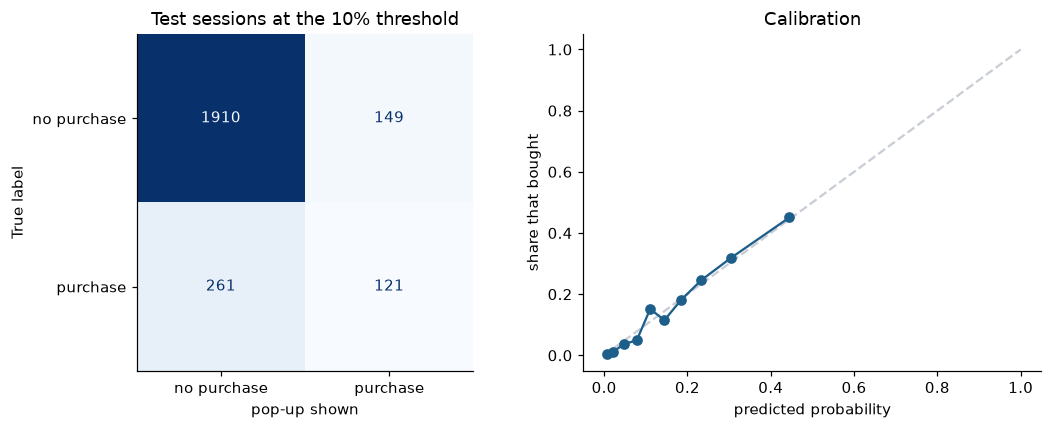

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, flags.astype(int), display_labels=["no purchase", "purchase"],
                                        ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_xlabel("pop-up shown")
axes[0].set_title("Test sessions at the 10% threshold")
from sklearn.calibration import calibration_curve
frac, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], "--", color="#c9ced6")
axes[1].plot(mean_pred, frac, "o-", color="#1d5f8a")
axes[1].set_xlabel("predicted probability")
axes[1].set_ylabel("share that bought")
axes[1].set_title("Calibration")
plt.tight_layout()
plt.show()

* **Errors at the threshold.** Most pop-ups that go to non-buyers are the cost of the 10% budget: the model is fairly
  sure about very few sessions without page value. Most buyers (about 70%) are *not* flagged. With a 10% budget and a
  15.6% buy rate, at most 64% of buyers could ever be reached, so missing many is built into the charter.
* **Calibration** is good. The points sit on the diagonal, so a "40%" really means about 40 in 100 such sessions
  buy. That lets the app show the probability as a plain number. Notice also that the points stop below 0.5. Without
  page value the model is almost never sure that a session will buy. It is good at saying "more likely than average",
  which is all a ranking for a 10% budget needs.

## 3. Error analysis by slice

Slices use every session scored by a model that never saw it: out-of-fold scores for the training rows and the final
model for the test rows. That gives five times more rows per slice than the test set alone.

In [5]:
slices = pd.read_csv(config.REPORTS_DIR / "slices.csv")
slices.round(3)

,slice,group,n,buy_rate,flag_rate,precision,recall,pr_auc
0,VisitorType,New_Visitor,1693,0.249,0.234,0.453,0.427,0.425
1,VisitorType,Other,81,0.198,0.210,0.353,0.375,0.326
2,VisitorType,Returning_Visitor,10431,0.141,0.080,0.438,0.248,0.360
3,Month,Aug,433,0.176,0.053,0.478,0.145,0.330
4,Month,Dec,1706,0.127,0.056,0.463,0.204,0.307
5,Month,Feb,181,0.017,0.000,NaN,0.000,0.076
6,Month,Jul,432,0.153,0.028,0.167,0.030,0.237
7,Month,Jun,285,0.102,0.025,0.429,0.103,0.229
8,Month,Mar,1860,0.103,0.030,0.357,0.104,0.283
9,Month,May,3329,0.110,0.031,0.442,0.126,0.337


**Where the model is wrong, and for whom.**

* **Season decides who gets the pop-ups.** With one fixed threshold, about 29% of November sessions are flagged and
  only about 4% of February to October sessions (February gets none). Precision stays about the same (0.40 to 0.46),
  so the model is not worse in quiet months. It just finds fewer sessions over the bar. In practice this means the
  10% budget would be blown in November and under-used in spring. **Fix: re-set the threshold each month, or cap pop-ups
  per day**, and the monitoring runbook watches the flag rate for exactly this.
* **New visitors** are flagged three times as often as returning visitors (23% against 8%), because they buy more often
  in this data (25% against 14%). Their precision (0.45) is as good as anyone's, so the charter's guardrail holds: new
  visitors are not shut out. A business might still decide that discounts for first-time visitors are a different
  policy question.
* **Weak slices.** July (precision 0.17 on only 12 flags) and traffic source 13 (6% buy rate) are where the model is
  least useful. These are small groups, so the numbers are noisy.
* **Weekend vs weekday** makes little difference.

## 4. What the model relies on

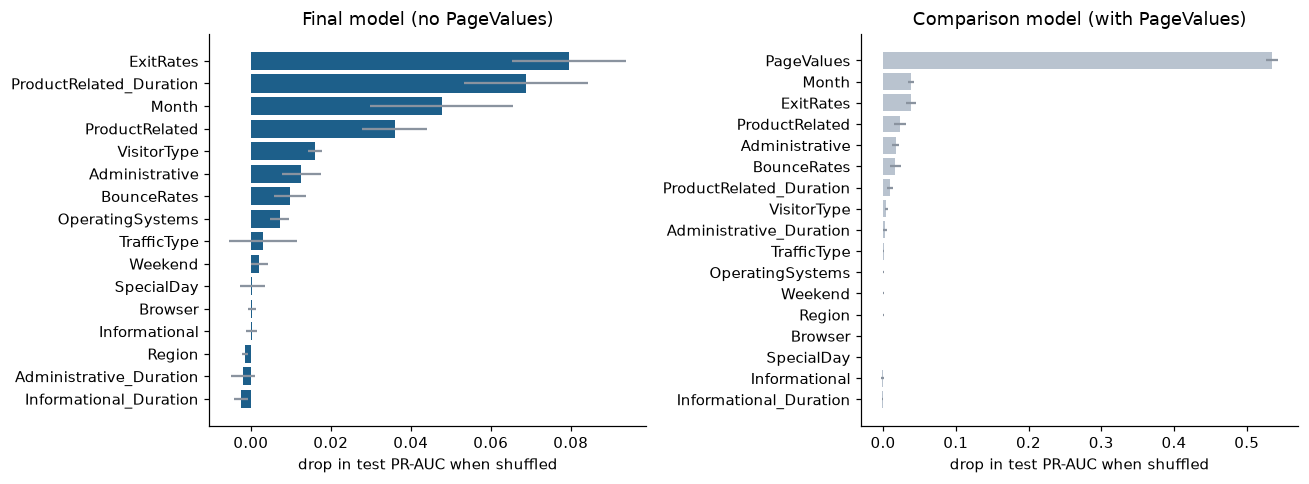

In [6]:
imp = pd.read_csv(config.REPORTS_DIR / "permutation_importance.csv").sort_values("importance_mean")
imp_pv = pd.read_csv(config.REPORTS_DIR / "permutation_importance_with_pagevalues.csv").sort_values("importance_mean")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(imp["feature"], imp["importance_mean"], xerr=imp["importance_std"], color="#1d5f8a", ecolor="#8a939f")
axes[0].set_title("Final model (no PageValues)")
axes[1].barh(imp_pv["feature"], imp_pv["importance_mean"], xerr=imp_pv["importance_std"], color="#b9c3cf", ecolor="#8a939f")
axes[1].set_title("Comparison model (with PageValues)")
for ax in axes:
    ax.set_xlabel("drop in test PR-AUC when shuffled")
plt.tight_layout()
plt.show()

* Without page value, the model leans on **exit rate**, **time on product pages**, **month** and **product page
  count**. These make sense for a shopper who is browsing seriously.
* With page value, shuffling that one column drops PR-AUC by about 0.53, and every other column almost vanishes.
  The comparison model is mostly a page-value lookup. That is one more reason not to trust its score.

## 5. Would we notice if the world changed? (PSI)

PSI (Population Stability Index) compares the distribution of each input with the training data. The usual rule is
under 0.1 stable, 0.1 to 0.25 watch, above 0.25 act.

In [7]:
psi_test = pd.read_csv(config.REPORTS_DIR / "psi_train_vs_test.csv")
psi_holiday = pd.read_csv(config.REPORTS_DIR / "psi_holiday_shift.csv")
display(psi_test.head(5).round(3))
display(psi_holiday.head(6).round(3))

,feature,psi,status
0,Browser,0.012,stable
1,TrafficType,0.010,stable
2,ExitRates,0.005,stable
3,Region,0.005,stable
4,OperatingSystems,0.004,stable


,feature,psi,status
0,TrafficType,0.811,act
1,SpecialDay,0.783,act
2,p_buy,0.353,act
3,ProductRelated_Duration,0.096,stable
4,VisitorType,0.091,stable
5,ProductRelated,0.085,stable


* **Train vs test** is stable everywhere (max PSI about 0.01). That is expected for a random split, and it is the
  "no alarm" baseline.
* **Simulated shift: the holiday season.** Comparing November and December sessions with February to October
  training sessions, `TrafficType` (0.81) and `SpecialDay` (0.78) fire the alarm, and so does the model's own score
  (0.35). Traffic sources change in the holidays (more campaign traffic), and `SpecialDay` is zero in Nov-Dec because
  the dataset only marks spring holidays. The score shift is the flag-rate problem from section 3. The alarm would fire
  in the first week of November, before any purchase labels arrive.

The month check run in MLflow (`month_check_train_feb_oct_test_nov_dec`) asks the harder question: a model trained only
on February to October, tested on November and December.

In [8]:
results = pd.read_csv(config.REPORTS_DIR / "results_table.csv").set_index("run")
results.loc[["month_check_train_feb_oct_test_nov_dec"], ["test_pr_auc", "test_roc_auc", "test_precision_at_10pct",
                                                         "test_prevalence"]].round(3)

,test_pr_auc,test_roc_auc,test_precision_at_10pct,test_prevalence
run,,,,
month_check_train_feb_oct_test_nov_dec,0.335,0.692,0.386,0.208


Trained without any holiday sessions, the model still reaches PR-AUC 0.34 on November and December, against 0.29
for Rule B on the same months. It degrades but still beats the rule. So the model is somewhat robust to the
season, and retraining once holiday data exists is still worth it.

## Summary

* The final model meets every offline criterion in the charter, without the leaky column.
* At the 10% budget, about 45 in 100 pop-ups go to visitors who buy, against about 16 at random.
* The biggest practical risk is the season: one fixed threshold over-spends in November. Re-set it monthly and watch
  the flag rate.
* What this data cannot answer: how many flagged visitors would have bought without the pop-up. That needs a live
  test with a hold-out group (see MONITORING.md).